# The phase-flip code in Qiskit: known phase vs. unknown phase
### dispersion is a phase you can undo · dephasing is one you can't · three qubits and two parity checks fix it

**In plain words.** This repo is about *phase*: a photodiode can't see it, dispersion moves it
around, and Gerchberg-Saxton gets it back. That works because dispersion is a **known** phase,
$e^{-iak^2}$, so it can be inverted. A quantum computer has a worse problem: **dephasing**, a
*random* phase kick on each qubit. Nobody knows which way it went, so it can't simply be inverted.

The fix is to spread one qubit's information over three, then check **parities** (do these two
qubits agree?) without ever looking at the data. One random phase flip changes a parity, which
points to the damaged qubit, which gets repaired. This notebook does that in **Qiskit**, with an
exact density-matrix simulation, and checks every number against closed-form math and against the
NumPy QEC module `dgs.quantum_error_correction`.

Free software (qiskit, numpy, sympy). Every figure uses the Okabe–Ito colorblind-safe palette,
distinguishes curves by line style as well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import qiskit_phase_flip as pf
from dgs import quantum_error_correction as q
import qiskit
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)
print("Qiskit", qiskit.__version__)

Qiskit 2.5.2


## 1. The circuit

* **Encode:** $\alpha|0\rangle+\beta|1\rangle \to \alpha|{+}{+}{+}\rangle+\beta|{-}{-}{-}\rangle$ (two CNOTs, three Hadamards).
* **Noise:** each data qubit gets $Z$ with probability $p$.
* **Detect:** Hadamards turn $Z$ errors into $X$ errors; ancilla `q3` records the parity of `q0, q1`, and `q4` the parity of `q1, q2`. These are the code's stabilizers $X_1X_2$ and $X_2X_3$.
* **Correct:** a multi-controlled $X$ fires for each syndrome pattern. This is the **deferred-measurement principle**: controlled gates do exactly what "measure the ancillas, then fix" would, so one noisy cycle is a unitary plus noise and can be simulated *exactly*.
* **Decode:** undo the CNOTs; `q0` holds the protected state.

In [2]:
print(pf.full_cycle_circuit().draw("text", fold=-1))

               ┌───┐ noise ┌───┐                    ┌───┐                    
q_0: ──■────■──┤ H ├───░───┤ H ├──■─────────────────┤ X ├────────────■────■──
     ┌─┴─┐  │  ├───┤   ░   ├───┤  │                 └─┬─┘┌───┐       │  ┌─┴─┐
q_1: ┤ X ├──┼──┤ H ├───░───┤ H ├──┼────■────■─────────┼──┤ X ├───────┼──┤ X ├
     └───┘┌─┴─┐├───┤   ░   ├───┤  │    │    │         │  └─┬─┘┌───┐┌─┴─┐└───┘
q_2: ─────┤ X ├┤ H ├───░───┤ H ├──┼────┼────┼────■────┼────┼──┤ X ├┤ X ├─────
          └───┘└───┘   ░   └───┘┌─┴─┐┌─┴─┐  │    │    │    │  └─┬─┘└───┘     
q_3: ──────────────────░────────┤ X ├┤ X ├──┼────┼────■────■────o────────────
                       ░        └───┘└───┘┌─┴─┐┌─┴─┐  │    │    │            
q_4: ──────────────────░──────────────────┤ X ├┤ X ├──o────■────■────────────
                       ░                  └───┘└───┘                         


## 2. Every single phase flip is fixed

Apply $Z$ to exactly one data qubit and check the output for all six Pauli eigenstates
$|0\rangle, |1\rangle, |{\pm}\rangle, |{\pm i}\rangle$:

In [3]:
from qiskit.quantum_info import Operator, partial_trace, state_fidelity
Zop = Operator(np.diag([1.0, -1.0]))
print(f"{'error':10s}" + "".join(f"{lbl:>8s}" for lbl in pf.PAULI_STATES))
for qubit in (None, 0, 1, 2):
    row = []
    for s in pf.PAULI_STATES.values():
        dm = pf._prepare(s).evolve(pf.encoder())
        if qubit is not None:
            dm = dm.evolve(Zop, qargs=[qubit])
        dm = dm.evolve(pf.syndrome_and_correct())
        row.append(state_fidelity(partial_trace(dm, [1, 2, 3, 4]), s))
    print(f"{'none' if qubit is None else f'Z on q{qubit}':10s}" + "".join(f"{f:8.4f}" for f in row))

error            0       1       +       -      +i      -i
none        1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Z on q0     1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Z on q1     1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Z on q2     1.0000  1.0000  1.0000  1.0000  1.0000  1.0000


## 3. Random dephasing: exact fidelity vs. the closed form

Two or more phase flips fool the parity checks. With independent flips of probability $p$:
$$p_L = 3p^2(1-p) + p^3 = 3p^2 - 2p^3$$
For a qubit channel, the fidelity averaged over the six Pauli states equals the average over all
pure states, and comes out as
$$\bar F_{\text{bare}} = 1 - \tfrac{2}{3}p, \qquad \bar F_{\text{code}} = 1 - \tfrac{2}{3}p_L$$

p_L = p at p = [1/2, 1] -> the code beats a bare qubit for p < 1/2


max |Qiskit exact - closed form| = 1.9e-15


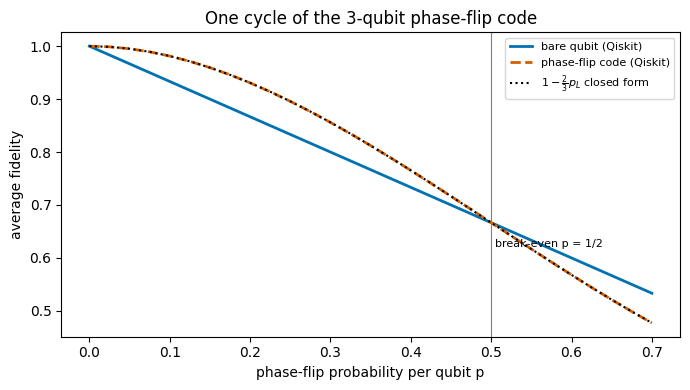

Figure: two curves start at fidelity 1. The bare qubit falls in a straight line; the coded qubit stays flatter (quadratic loss) until they cross at p = 1/2, after which the code is worse. The dotted closed form lies on top of the coded curve.


In [4]:
p = sp.symbols("p", positive=True)
pL = q.logical_error_symbolic(3)
display(sp.Eq(sp.Symbol("p_L"), pL))
print("p_L = p at p =", sp.solve(sp.Eq(pL, p), p), "-> the code beats a bare qubit for p < 1/2")

ps = np.linspace(0, 0.7, 29)
F_code = [pf.average_fidelity(pf.dephasing(x)) for x in ps]
F_bare = [pf.average_fidelity(pf.dephasing(x), encoded=False) for x in ps]
err = max(abs(a - pf.average_fidelity_theory(x)) for a, x in zip(F_code, ps))
print(f"max |Qiskit exact - closed form| = {err:.1e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ps, F_bare, "-", lw=2, label="bare qubit (Qiskit)")
ax.plot(ps, F_code, "--", lw=2, label="phase-flip code (Qiskit)")
ax.plot(ps, [pf.average_fidelity_theory(x) for x in ps], ":", color="k", label=r"$1-\frac{2}{3}p_L$ closed form")
ax.axvline(0.5, color="gray", lw=0.8); ax.text(0.505, 0.62, "break-even p = 1/2", fontsize=8)
ax.set_xlabel("phase-flip probability per qubit p"); ax.set_ylabel("average fidelity"); ax.legend(fontsize=8)
ax.set_title("One cycle of the 3-qubit phase-flip code"); plt.tight_layout(); plt.show()
print("Figure: two curves start at fidelity 1. The bare qubit falls in a straight line; the coded qubit stays "
      "flatter (quadratic loss) until they cross at p = 1/2, after which the code is worse. The dotted closed form "
      "lies on top of the coded curve.")

## 4. A systematic phase: what dispersion left uncompensated would do

If every qubit gets the *same* small phase, $e^{-i\theta Z}$ (a coherent error, like a bit of
residual dispersion), a bare qubit loses fidelity like $\theta^2$. The code turns each single-qubit
term into a correctable flip, so only the two-qubit terms (amplitude $\sim\theta^2$) survive:
infidelity $\sim\theta^4$.

log-log slope: bare 2.00 (theory 2), coded 4.00 (theory 4)


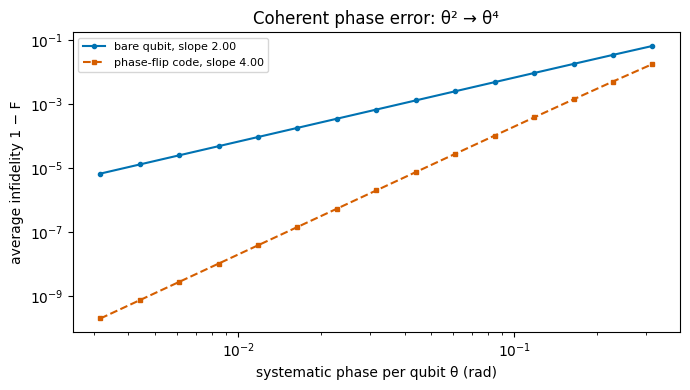

Figure: on log-log axes both infidelities are straight lines. The coded line is twice as steep, so at θ = 0.01 rad the code is about four orders of magnitude better.


In [5]:
th = np.logspace(-2.5, -0.5, 15)
bare = np.array([1 - pf.average_fidelity(pf.coherent_phase(t), encoded=False) for t in th])
coded = np.array([1 - pf.average_fidelity(pf.coherent_phase(t)) for t in th])
s_bare = np.polyfit(np.log(th[:8]), np.log(bare[:8]), 1)[0]
s_coded = np.polyfit(np.log(th[:8]), np.log(coded[:8]), 1)[0]
print(f"log-log slope: bare {s_bare:.2f} (theory 2), coded {s_coded:.2f} (theory 4)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(th, bare, "-o", ms=3, label=f"bare qubit, slope {s_bare:.2f}")
ax.loglog(th, coded, "--s", ms=3, label=f"phase-flip code, slope {s_coded:.2f}")
ax.set_xlabel("systematic phase per qubit θ (rad)"); ax.set_ylabel("average infidelity 1 − F"); ax.legend(fontsize=8)
ax.set_title("Coherent phase error: θ² → θ⁴"); plt.tight_layout(); plt.show()
print("Figure: on log-log axes both infidelities are straight lines. The coded line is twice as steep, so at "
      "θ = 0.01 rad the code is about four orders of magnitude better.")

## 5. What an experiment would see: shots and confidence intervals

On hardware you don't get the density matrix, you get counts. Prepare $|0\rangle$, run one noisy
cycle, measure `q0`: each `1` is a logical failure. With $S$ shots the estimate $\hat p_L = k/S$
is binomial; the **Wilson interval** gives a 95% range that behaves well even at $k = 0$.

In [6]:
p0 = 0.05
true_pL = q.logical_error(p0, 3)
print(f"p = {p0}: true p_L = {true_pL:.5f}\n")
print(f"{'shots':>7s} {'estimate':>10s} {'95% Wilson interval':>26s} {'covers truth':>13s}")
for S in (1, 10, 100, 1000, 10_000, 100_000):
    est, (lo, hi) = pf.logical_error_rate_from_shots(p0, S, rng=S)
    print(f"{S:7d} {est:10.5f}   [{lo:.5f}, {hi:.5f}]   {str(lo <= true_pL <= hi):>12s}")

# coverage check: how often does the 95% interval contain the truth?
rng = np.random.default_rng(0)
print("(a single miss among six rows is expected: each interval misses 5% of the time)")
hits = sum(lo <= true_pL <= hi for lo, hi in (pf.logical_error_rate_from_shots(p0, 1000, rng=rng)[1] for _ in range(2000)))
print(f"\ncoverage over 2000 repeats at 1000 shots: {hits/2000:.3f} (target 0.95)")

p = 0.05: true p_L = 0.00725

  shots   estimate        95% Wilson interval  covers truth
      1    0.00000   [0.00000, 0.79345]           True
     10    0.10000   [0.01788, 0.40415]          False
    100    0.01000   [0.00177, 0.05449]           True
   1000    0.00700   [0.00339, 0.01438]           True
  10000    0.00590   [0.00458, 0.00760]           True
 100000    0.00709   [0.00659, 0.00763]           True
(a single miss among six rows is expected: each interval misses 5% of the time)



coverage over 2000 repeats at 1000 shots: 0.957 (target 0.95)


## 6. Where this goes next

| idea | equation / object | in this repo |
|---|---|---|
| known phase (dispersion) | $D(a)=\mathrm{QFT}^{-1}e^{-iak^2}\mathrm{QFT}$, inverted by GS | `projects/tdgsa_qis/` |
| unknown phase (dephasing) | $Z$ with probability $p$ | this notebook |
| one logical qubit, 3 physical | $p_L = 3p^2-2p^3$, break-even $p=1/2$ | `dgs.qiskit_phase_flip` |
| coherent error suppression | $1-F \sim \theta^2 \to \theta^4$ | section 4 |
| bigger codes, thresholds, matching | repetition $d=3,5,7$, MWPM decoder | `quantum_error_correction` |
| both bit and phase flips | Shor 9-qubit, Steane 7-qubit | next step |

**Honest limits:** one correction cycle; perfect gates and ancillas (code-capacity noise); no
measurement errors. Adding noisy ancillas is what makes real thresholds drop to about 1%.

*Exact density-matrix simulation with qiskit.quantum_info. Education.*